# Berlin v7.1: Real-Time-Ratio nach CPU-Anzahl

Vergleich der pct-Fälle anhand der **ersten Datenzeile** (erste Iteration, ohne CSV-Header) aus jeder `instrument/instrument_process_0.csv`.

$$\mathrm{RealTimeRatio} = \frac{36 \cdot 3600}{\mathrm{duration\_ns} / 10^9}$$

Die simulierte Zeit beträgt 36 Stunden. Eine größere Ratio bedeutet eine schnellere Simulation.

**CPU-Zählung:** `#CPUs` entspricht der Thread-Zahl in `iterations_<N>threads_<Job-ID>`. Die Slurm-Skripte reservieren unabhängig davon 192 CPUs pro Job; der Plot zeigt die verwendete Thread-Zahl.

Benötigt: Python, pandas und matplotlib. Den gemounteten Datenpfad bei Bedarf in der nächsten Zelle anpassen.

In [1]:
from pathlib import Path
import re
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import display

DATA_ROOT = Path("/Users/paulh/hlrn-cluster/iterations-rust/parallel-qsim-berlin/output/v7.1")
SIMULATED_SECONDS = 36 * 3600

In [2]:
def load_first_iterations(data_root):
    """Lade die erste Datenzeile pro Lauf, mit Laufzeit in Sekunden."""
    if not data_root.is_dir():
        raise FileNotFoundError(f"Datenpfad nicht vorhanden oder nicht gemountet: {data_root}")

    records = []
    skipped = []
    for pct_dir in sorted(data_root.glob("*pct")):
        pct_match = re.fullmatch(r"(\d+(?:\.\d+)?)pct", pct_dir.name)
        if not pct_dir.is_dir() or pct_match is None:
            continue
        pct = float(pct_match.group(1))
        for run_dir in sorted(pct_dir.glob("iterations_*threads_*")):
            run_match = re.fullmatch(r"iterations_(\d+)threads_(.+)", run_dir.name)
            if not run_dir.is_dir() or run_match is None:
                continue
            instrument = run_dir / "instrument" / "instrument_process_0.csv"
            if not instrument.is_file():
                skipped.append({"run": str(run_dir.relative_to(data_root)), "reason": "Instrument-Datei fehlt"})
                continue
            try:
                first = pd.read_csv(instrument, nrows=1)
            except pd.errors.EmptyDataError:
                first = pd.DataFrame()
            if first.empty:
                skipped.append({"run": str(run_dir.relative_to(data_root)), "reason": "Keine Datenzeile vorhanden"})
                continue

            row = first.iloc[0]
            if row["func_name"] != "run":
                raise ValueError(f"Erste Datenzeile enthält keine Simulationslaufzeit: {instrument}")
            duration_ns = float(row["duration_ns"])
            if not 0 < duration_ns < float("inf"):
                raise ValueError(f"Ungültige Laufzeit {duration_ns} in {instrument}")
            runtime_seconds = duration_ns / 1e9
            records.append({
                "pct": pct,
                "cpus": int(run_match.group(1)),
                "run": run_dir.name,
                "runtime_seconds": runtime_seconds,
                "real_time_ratio": SIMULATED_SECONDS / runtime_seconds,
                "instrument_file": str(instrument),
            })

    if not records:
        raise ValueError(f"Keine auswertbaren Instrument-Dateien unter {data_root}")
    results = pd.DataFrame(records).sort_values(["pct", "cpus", "run"]).reset_index(drop=True)
    return results, pd.DataFrame(skipped, columns=["run", "reason"])

results, skipped = load_first_iterations(DATA_ROOT)
print(f"{len(results)} Läufe geladen; {len(skipped)} Läufe übersprungen.")
if not skipped.empty:
    warnings.warn("Unvollständige Läufe wurden übersprungen; siehe Tabelle.", stacklevel=1)
    display(skipped)

17 Läufe geladen; 1 Läufe übersprungen.


/var/folders/kf/jtljxz_d0hn25x3w4fr2xrw00000gn/T/ipykernel_15649/1967321937.py:53: UserWarning: Unvollständige Läufe wurden übersprungen; siehe Tabelle.
  warnings.warn("Unvollständige Läufe wurden übersprungen; siehe Tabelle.", stacklevel=1)


,run,reason
0,10pct/iterations_1threads_9551382-1,Keine Datenzeile vorhanden


In [3]:
# Die Quelldateien bleiben über results["instrument_file"] nachvollziehbar.
display(results[["pct", "cpus", "runtime_seconds", "real_time_ratio"]].style.format({
    "pct": "{:g}%",
    "runtime_seconds": "{:.3f}",
    "real_time_ratio": "{:.2f}",
}))

,pct,cpus,runtime_seconds,real_time_ratio
0,1%,1,32.033,4045.81
1,1%,2,30.542,4243.33
2,1%,4,22.039,5880.61
3,1%,8,11.078,11699.10
4,1%,16,6.766,19155.18
5,1%,32,4.712,27502.16
6,1%,64,4.952,26170.99
7,1%,128,7.569,17122.99
8,1%,192,5.652,22931.07
9,10%,2,505.932,256.16


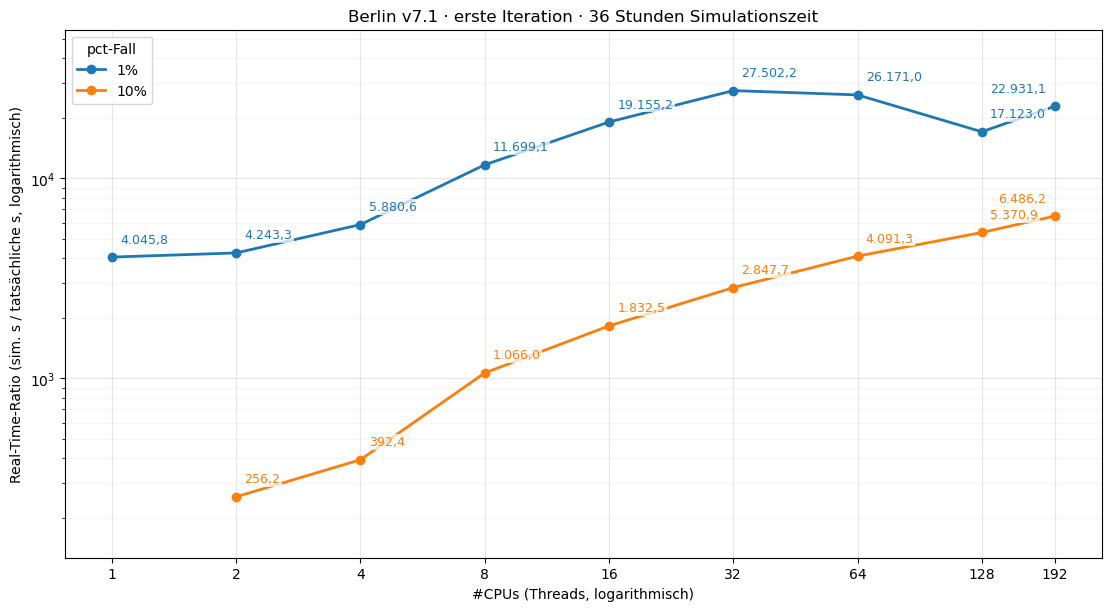

In [4]:
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
colors = plt.get_cmap("tab10")
for index, (pct, group) in enumerate(results.groupby("pct", sort=True)):
    group = group.sort_values("cpus")
    color = colors(index % 10)
    ax.plot(
        group["cpus"], group["real_time_ratio"],
        marker="o", linewidth=2, markersize=6,
        color=color, label=f"{pct:g}%",
    )
    for row in group.itertuples():
        # Deutsche Zahlendarstellung, auf eine Nachkommastelle gerundet.
        label = f"{row.real_time_ratio:,.1f}".replace(",", "_").replace(".", ",").replace("_", ".")
        last_point = row.cpus == group["cpus"].max()
        ax.annotate(
            label, xy=(row.cpus, row.real_time_ratio),
            xytext=(-6 if last_point else 6, 8), textcoords="offset points",
            ha="right" if last_point else "left", va="bottom",
            fontsize=9, color=color,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
        )

ax.set_xscale("log", base=2)
ax.set_yscale("log", base=10)
ax.set(
    xlabel="#CPUs (Threads, logarithmisch)",
    ylabel="Real-Time-Ratio (sim. s / tatsächliche s, logarithmisch)",
    title="Berlin v7.1 · erste Iteration · 36 Stunden Simulationszeit",
)
ax.margins(y=0.15)
ax.set_xticks(sorted(results["cpus"].unique()))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.grid(True, which="major", alpha=0.3)
ax.grid(True, which="minor", alpha=0.12)
ax.legend(title="pct-Fall")
plt.show()